# Model training - Sentiment Classification

This notebook develops a baseline machine learning model to classify Brazilian e-commercer customer reviews into three sentiment categories: positive, negative and neutral.

The first approach uses TF-IDF for text representation and Logistic Regression for classification.

## Objectives
- Load the prepared dataset.
- Split the data into training and testing sets.
- Convert text into numerical features using TF-IDF.
- Train a Logistic Regression classifier.
- Evaluate model performance using appropriate classification metrics.


In [16]:
# Import Libraries

import pandas as pd
import numpy as np
 
from pathlib import Path

from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load the prepared dataset

possible_path = [
    Path("data/processed/reviews_cleaned.cv"),
    Path("../data/processed/reviews_cleaned.csv")
]

data_path = next(
    (path for path in possible_path if path.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError("Prepared dataset not found. Please check the file path.")

df = pd.read_csv(data_path, encoding="utf-8")

print("Dataset loaded successfully")
print("File path:", data_path.resolve())
print("Dataset shape:", df.shape)

print("Columns:")
print(df.columns.tolist())

print("\nFirst 5 reviews:")
display(df[["review_text", "review_score", "Sentiment"]].head()) 

print("\nMissing values:")
print(df[["review_text", "Sentiment"]].isna().sum())

print("\nSentiment distribution:")
print(df["Sentiment"].value_counts())


In [ ]:
from sklearn.model_selection import train_test_split

X = df["review_text"]
y = df["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

print("\nTraining samples:", len(X_train))
print("\nTesting samples:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True).round(3))



In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

#Initialize the TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2),
    min_df=2
)

#Fit and transform training data
X_train_tfidf = tfidf.fit_transform(X_train)

#Transform testing data
X_test_tfidf = tfidf.transform(X_test)

#Resulting matrices
print("\nTraining matriz shape:", X_train_tfidf.shape)
print("\nTesting matrix shape:", X_test_tfidf.shape)
print("\nVocabulary size:", len(tfidf.vocabulary_))


In [ ]:
from sklearn.linear_model import LogisticRegression

#Initialize the Logistic Regression model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

#Train model
model.fit(X_train_tfidf, y_train)
print("\nModel trained successfully!")

#Predict sentiments on the test set
y_pred = model.predict(X_test_tfidf)

#Display 10 first predictions
for text, actual, predicted in zip(
    X_test.head(10),
    y_test.head(10),
    y_pred[:10]
):
    print("Review:", text)
    print("Actual sentiment:", actual)
    print("Predicted sentiment:", predicted)
    print("-" * 80)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

#Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

#Calculate macro F1-score
macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("Model evaluation")
print("_" * 40)

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")

print("\nClassification report")
print(classification_report(y_test, y_pred))

print("\nCONFUSION MATRIX")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["negative", "neutral", "positive"]
))

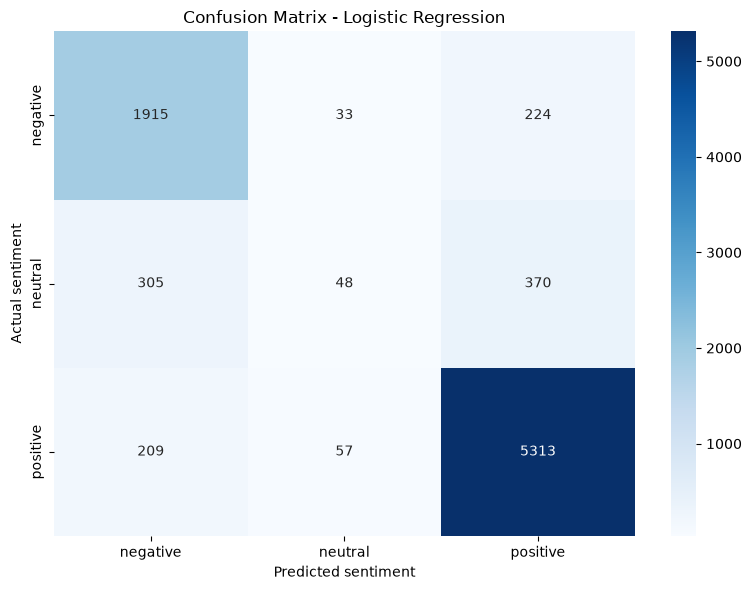

In [19]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = ["negative", "neutral", "positive"]

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()


In [ ]:

# Initialize a balanced Logistic Regression model
model_balanced = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

# Train the model
model_balanced.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_balanced = model_balanced.predict(X_test_tfidf)

# Evaluate the balanced model
print("BALANCED LOGISTIC REGRESSION")
print("-" * 40)

print(classification_report(y_test, y_pred_balanced))

print(
    "Macro F1-score:",
    round(f1_score(y_test, y_pred_balanced, average="macro"), 4)
)


In [ ]:

labels = ["negative", "neutral", "positive"]

cm_balanced = confusion_matrix(
    y_test,
    y_pred_balanced,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import pandas as pd

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Balanced Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_balanced)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred, average="macro"),
        f1_score(y_test, y_pred_balanced, average="macro")
    ],
    "Neutral F1": [
        f1_score(y_test, y_pred, average="macro", labels=["neutral"]),
        f1_score(y_test, y_pred_balanced, average="macro", labels=["neutral"])
    ],
    "Neutral Recall": [
        recall_score(y_test, y_pred, labels=["neutral"], average="macro"),
        recall_score(y_test, y_pred_balanced, labels=["neutral"], average="macro")
    ]
})

display(results.round(4))


In [ ]:

# Create a DataFrame with actual and predicted sentiments
error_analysis = pd.DataFrame({
    "review_text": X_test,
    "actual": y_test,
    "predicted": y_pred_balanced
})

# Filter incorrectly classified reviews
errors = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
].copy()

print("Total incorrect predictions:", len(errors))

# Show examples of neutral reviews predicted as positive
neutral_as_positive = errors[
    (errors["actual"] == "neutral") &
    (errors["predicted"] == "positive")
]

print("\nNEUTRAL PREDICTED AS POSITIVE:")
display(neutral_as_positive[["review_text", "actual", "predicted"]].head(10))

# Show examples of positive reviews predicted as neutral
positive_as_neutral = errors[
    (errors["actual"] == "positive") &
    (errors["predicted"] == "neutral")
]

print("\nPOSITIVE PREDICTED AS NEUTRAL:")
display(positive_as_neutral[["review_text", "actual", "predicted"]].head(10))


In [ ]:

# Rebuild error analysis with the original review scores
error_analysis = pd.DataFrame({
    "review_text": X_test.reset_index(drop=True),
    "review_score": df.loc[X_test.index, "review_score"].reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": y_pred_balanced
})

# Keep only incorrect predictions
errors = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
].copy()

# Inspect neutral reviews predicted as positive
print("NEUTRAL PREDICTED AS POSITIVE:")
display(
    errors[
        (errors["actual"] == "neutral") &
        (errors["predicted"] == "positive")
    ][["review_text", "review_score", "actual", "predicted"]].head(15)
)

# Inspect positive reviews predicted as neutral
print("\nPOSITIVE PREDICTED AS NEUTRAL:")
display(
    errors[
        (errors["actual"] == "positive") &
        (errors["predicted"] == "neutral")
    ][["review_text", "review_score", "actual", "predicted"]].head(15)
)


In [ ]:

# Save error analysis results
errors.to_csv(
    "reports/baseline_error_analysis.csv",
    index=False,
    encoding="utf-8"
)

print("Error analysis saved successfully!")
print("Total errors:", len(errors))


In [ ]:

# Improved TF-IDF configuration
tfidf_improved = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 3),
    min_df=2,
    sublinear_tf=True
)

# Fit on training data and transform
X_train_tfidf_improved = tfidf_improved.fit_transform(X_train)

# Transform test data using the same vocabulary
X_test_tfidf_improved = tfidf_improved.transform(X_test)

print("Improved training matrix:", X_train_tfidf_improved.shape)
print("Improved testing matrix:", X_test_tfidf_improved.shape)
print("Vocabulary size:", len(tfidf_improved.vocabulary_))


# Train improved Logistic Regression
model_improved = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

model_improved.fit(X_train_tfidf_improved, y_train)

# Make predictions
y_pred_improved = model_improved.predict(X_test_tfidf_improved)

# Evaluate
print(classification_report(y_test, y_pred_improved))

print(
    "Macro F1:",
    round(f1_score(y_test, y_pred_improved, average="macro"), 4)
)


In [ ]:

comparison_df.to_csv(
    "reports/model_comparison.csv",
    index=False,
    encoding="utf-8"
)

print("Model comparison saved successfully!")


### Baseline Experiments — Conclusions

Three Logistic Regression experiments were conducted using TF-IDF text representations.

1. **Logistic Regression:** established the initial baseline, achieving an accuracy of 85.86% and a Macro F1-score of 0.6230.
2. **Balanced Logistic Regression:** used class weighting to address class imbalance, improving Macro F1 to 0.6688 and substantially increasing neutral-class recall.
3. **Improved TF-IDF + Balanced Logistic Regression:** tested a larger vocabulary, n-grams up to three words, and sublinear term frequency. It did not demonstrate a substantial improvement over the balanced baseline.

**Key findings:**
- Class imbalance significantly affected neutral sentiment classification.
- Class weighting improved the balance between sentiment classes.
- Increasing TF-IDF vocabulary size did not produce a meaningful performance gain.
- Error analysis revealed potential inconsistencies between review text and sentiment labels derived from review scores.

The balanced Logistic Regression model was selected as the current reference baseline based on Macro F1. Further comparison with a transformer-based model will be conducted.